# Домашнее задание 4.1. Метод стрельбы для маятника

**Задача.** Для заданного начального угла подобрать начальную угловую скорость $s=\dot\theta(0)$, чтобы в момент $T$ маятник пришёл в нужное положение.

Используем метод стрельбы: при каждом пробном $s$ решаем задачу Коши и вычисляем невязку $R(s)=\theta(T;s)-\theta_{\mathrm{цель}}$. Затем ищем нуль $R(s)$.

В обеих частях задача Коши интегрируется **методом Рунге — Кутты 4-го порядка (RK4)** с фиксированным шагом. Это позволяет отдельно проверить влияние шага интегрирования и точности поиска корня.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image
import os
import tempfile

plt.rcParams.update({"figure.figsize": (9, 4.7), "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

/usr/local/lib/python3.12/dist-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Численный интегратор

Уравнение маятника записывается как система первого порядка:

$$
\dot\theta=\omega, \qquad
\dot\omega=\begin{cases}-\theta, & \text{линейный маятник},\\
-\sin\theta, & \text{нелинейный маятник}.
\end{cases}
$$

Функция ниже возвращает конечный угол или всю траекторию. Число шагов выбирается так, чтобы последний момент времени точно совпадал с $T$.

In [2]:
def rk4(s, T, h, nonlinear=False, trajectory=False):
    n = int(np.ceil(T / h))
    dt = T / n
    theta, omega = 0.0, float(s)

    if trajectory:
        times = np.linspace(0.0, T, n + 1)
        angles = np.empty(n + 1)
        angles[0] = theta

    def acceleration(angle):
        return -np.sin(angle) if nonlinear else -angle

    for i in range(n):
        a1 = omega
        b1 = acceleration(theta)
        a2 = omega + dt * b1 / 2
        b2 = acceleration(theta + dt * a1 / 2)
        a3 = omega + dt * b2 / 2
        b3 = acceleration(theta + dt * a2 / 2)
        a4 = omega + dt * b3
        b4 = acceleration(theta + dt * a3)

        theta += dt * (a1 + 2*a2 + 2*a3 + a4) / 6
        omega += dt * (b1 + 2*b2 + 2*b3 + b4) / 6
        if trajectory:
            angles[i + 1] = theta

    return (times, angles) if trajectory else theta

## 2. Линейный маятник

Решаем задачу

$$\ddot\theta+\theta=0,\qquad \theta(0)=0,\qquad \theta(2)=0.2.$$

Для выбранного $s$ невязка равна $R(s)=\theta(2;s)-0.2$. Точное решение известно:

$$\theta_{\mathrm{точн}}(t)=\frac{0.2\sin t}{\sin 2},\qquad
s_{\mathrm{точн}}=\frac{0.2}{\sin 2}.$$

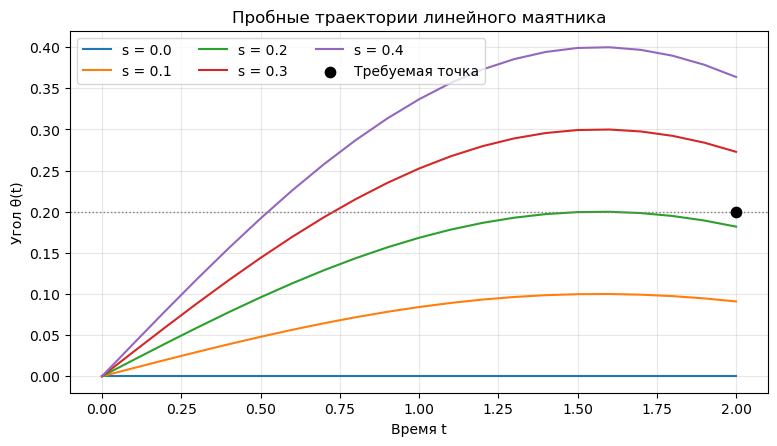

Точная начальная скорость: s = 0.2199500341


In [3]:
T_linear = 2.0
target = 0.2
h_linear = 0.1
s_exact = target / np.sin(T_linear)

def residual_linear(s, h=h_linear):
    return rk4(s, T_linear, h) - target

fig, ax = plt.subplots()
for s in [0.0, 0.1, 0.2, 0.3, 0.4]:
    t, theta = rk4(s, T_linear, h_linear, trajectory=True)
    ax.plot(t, theta, label=f's = {s:.1f}')
ax.scatter([T_linear], [target], color='black', s=55, zorder=5, label='Требуемая точка')
ax.axhline(target, color='gray', linestyle=':', linewidth=1)
ax.set(xlabel='Время t', ylabel='Угол θ(t)', title='Пробные траектории линейного маятника')
ax.legend(ncol=3)
plt.show()
print(f'Точная начальная скорость: s = {s_exact:.10f}')

### 2.1. Поиск скорости методом Ньютона и бисекции

Метод Ньютона обновляет скорость по формуле

$$s_{k+1}=s_k-\frac{R(s_k)}{R'(s_k)}.$$

Производную вычисляем центральной разностью: $R'(s)\approx [R(s+\varepsilon)-R(s-\varepsilon)]/(2\varepsilon)$. Поэтому одна итерация требует дополнительных вычислений задачи Коши.

Метод бисекции не использует производную, но требует отрезок, на концах которого невязка имеет разные знаки.

In [4]:
class CountResidual:
    def __init__(self, func):
        self.func = func
        self.calls = 0

    def __call__(self, s):
        self.calls += 1
        return self.func(s)


def newton(f, x0, tol=1e-11, derivative_step=1e-5, maxiter=30):
    x = float(x0)
    history = []
    for k in range(maxiter + 1):
        r = f(x)
        history.append((k, x, r))
        if abs(r) < tol:
            return x, history, 'сошёлся'
        if k == maxiter:
            break
        d = (f(x + derivative_step) - f(x - derivative_step)) / (2*derivative_step)
        if not np.isfinite(d) or abs(d) < 1e-9:
            return x, history, 'малая производная'
        x -= r / d
        if not np.isfinite(x) or abs(x) > 20:
            return x, history, 'слишком большой шаг Ньютона'
    return x, history, 'достигнут предел итераций'


def bisection(f, a, b, tol=1e-11, maxiter=100):
    fa, fb = f(a), f(b)
    if fa * fb >= 0:
        raise ValueError('На концах интервала нужны разные знаки невязки')
    history = []
    for k in range(maxiter):
        mid = (a + b) / 2
        fm = f(mid)
        history.append((k, mid, fm))
        if abs(fm) < tol:
            return mid, history
        if fa * fm < 0:
            b, fb = mid, fm
        else:
            a, fa = mid, fm
    return mid, history

count_n = CountResidual(residual_linear)
s_newton, hist_n, status_n = newton(count_n, x0=0.4)
count_b = CountResidual(residual_linear)
s_bisect, hist_b = bisection(count_b, 0.0, 0.5)

comparison = pd.DataFrame([
    ['Ньютон', s_newton, len(hist_n)-1, count_n.calls, abs(s_newton - s_exact)],
    ['Бисекция', s_bisect, len(hist_b), count_b.calls, abs(s_bisect - s_exact)]
], columns=['Метод', 'Найденное s', 'Итерации', 'Вычисления R(s)', 'Ошибка по s'])
display(comparison)

,Метод,Найденное s,Итерации,Вычисления R(s),Ошибка по s
0,Ньютон,0.21995,1,4,1.366583e-07
1,Бисекция,0.21995,34,36,1.366511e-07


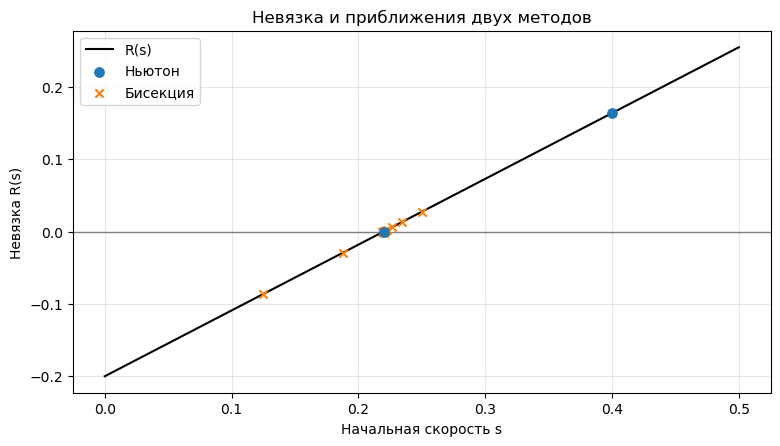

In [5]:
s_grid = np.linspace(0, 0.5, 220)
r_grid = np.array([residual_linear(s) for s in s_grid])
fig, ax = plt.subplots()
ax.plot(s_grid, r_grid, color='black', label='R(s)')
ax.axhline(0, color='gray', linewidth=1)
ax.scatter([row[1] for row in hist_n], [row[2] for row in hist_n],
           color='tab:blue', s=45, zorder=4, label='Ньютон')
ax.scatter([row[1] for row in hist_b], [row[2] for row in hist_b],
           color='tab:orange', marker='x', s=35, zorder=3, label='Бисекция')
ax.set(xlabel='Начальная скорость s', ylabel='Невязка R(s)',
       title='Невязка и приближения двух методов')
ax.legend()
plt.show()

### 2.2. Проверка точности интегрирования

Для каждого значения шага заново находим $s_h$, а затем сравниваем полученную траекторию с точной. У RK4 ожидается ошибка порядка $h^4$ до достижения предела округления.

,Шаг h,Подобранная скорость,|s_h - s_точн|,Макс. ошибка траектории
0,0.400,0.219940,9.842499e-06,4.556975e-05
1,0.200,0.219948,1.673301e-06,3.379217e-06
2,0.100,0.219950,1.366600e-07,2.278756e-07
3,0.050,0.219950,9.521895e-09,1.467382e-08
4,0.025,0.219950,6.253736e-10,9.302563e-10


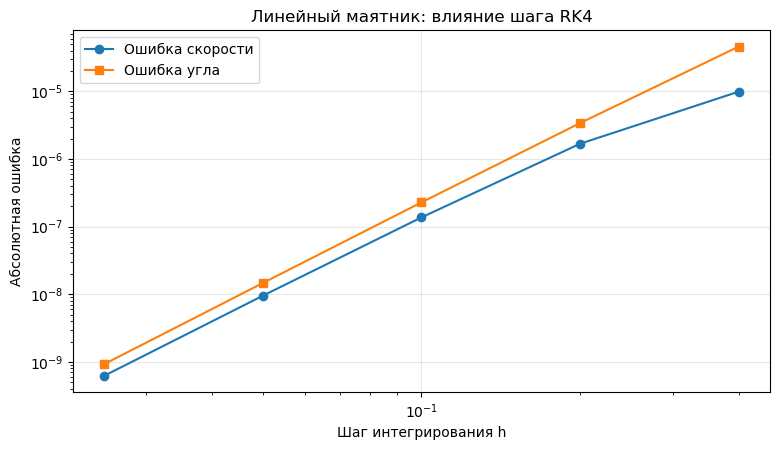

In [6]:
steps_linear = [0.4, 0.2, 0.1, 0.05, 0.025]
linear_rows = []
for h in steps_linear:
    f = lambda s: residual_linear(s, h)
    sh = brentq(f, 0.0, 0.5, xtol=1e-14)
    t, angles = rk4(sh, T_linear, h, trajectory=True)
    err_path = np.max(np.abs(angles - s_exact * np.sin(t)))
    linear_rows.append([h, sh, abs(sh-s_exact), err_path])
linear_accuracy = pd.DataFrame(linear_rows,
    columns=['Шаг h', 'Подобранная скорость', '|s_h - s_точн|', 'Макс. ошибка траектории'])
display(linear_accuracy)

fig, ax = plt.subplots()
ax.loglog(linear_accuracy['Шаг h'], linear_accuracy['|s_h - s_точн|'], 'o-', label='Ошибка скорости')
ax.loglog(linear_accuracy['Шаг h'], linear_accuracy['Макс. ошибка траектории'], 's-', label='Ошибка угла')
ax.set(xlabel='Шаг интегрирования h', ylabel='Абсолютная ошибка',
       title='Линейный маятник: влияние шага RK4')
ax.legend()
plt.show()

Уменьшение допуска поиска корня не обязательно улучшает движение: при фиксированном шаге мы точно решаем приближённое уравнение $R_h(s)=0$, а не исходное $R(s)=0$. После достижения ошибки интегрирования дальнейшее ужесточение допуска почти бесполезно.

In [7]:
fixed_h = 0.2
rows_tol = []
for tol in [1e-4, 1e-7, 1e-10, 1e-13]:
    f = lambda s: residual_linear(s, fixed_h)
    found, history = bisection(f, 0.0, 0.5, tol=tol)
    t, theta = rk4(found, T_linear, fixed_h, trajectory=True)
    rows_tol.append([tol, len(history), abs(found - s_exact),
                     np.max(np.abs(theta - s_exact*np.sin(t)))])
display(pd.DataFrame(rows_tol, columns=['Допуск по |R|', 'Итерации', 'Ошибка скорости', 'Макс. ошибка угла']))

,Допуск по |R|,Итерации,Ошибка скорости,Макс. ошибка угла
0,1.000000e-04,11,0.000021,0.000020
1,1.000000e-07,20,0.000002,0.000003
2,1.000000e-10,28,0.000002,0.000003
3,1.000000e-13,40,0.000002,0.000003


## 3. Нелинейный маятник

Теперь рассматриваем

$$\ddot\theta+\sin\theta=0,\qquad \theta(0)=0,\qquad \theta(4)=0.$$

Невязка имеет вид $R(s)=\theta(4;s)$. Важно, что в конечный момент нужен угол ровный $0$, а не произвольный угол, кратный $2\pi$.

Исследуем $s\in[-1.99,1.99]$. Чтобы получить все корни, сначала смотрим на график невязки и ищем промежутки со сменой знака.

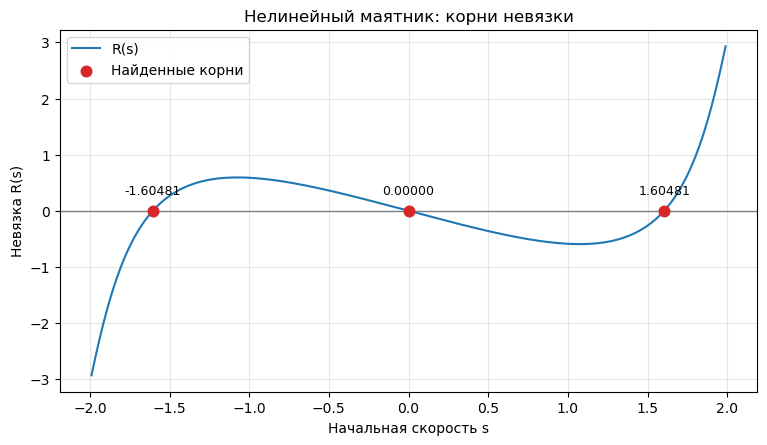

Найденные начальные скорости: -1.604813034, 0.000000000, 1.604813034


In [8]:
T_nonlin = 4.0
h_nonlin = 0.02

def residual_nonlin(s, h=h_nonlin):
    return rk4(s, T_nonlin, h, nonlinear=True)

s_scan = np.linspace(-1.99, 1.99, 1001)
r_scan = np.array([residual_nonlin(s) for s in s_scan])
intervals = [(s_scan[i], s_scan[i+1]) for i in range(len(s_scan)-1)
             if r_scan[i] * r_scan[i+1] < 0]
roots = [brentq(residual_nonlin, a, b, xtol=1e-12) for a, b in intervals]
roots += [float(s_scan[i]) for i in range(len(s_scan)) if abs(r_scan[i]) < 1e-12]
roots = np.array(sorted(set(np.round(roots, 11))))

fig, ax = plt.subplots()
ax.plot(s_scan, r_scan, label='R(s)')
ax.axhline(0, color='gray', linewidth=1)
ax.scatter(roots, np.zeros_like(roots), color='tab:red', s=58, zorder=5, label='Найденные корни')
for root in roots:
    ax.annotate(f'{root:.5f}', (root, 0), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=9)
ax.set(xlabel='Начальная скорость s', ylabel='Невязка R(s)',
       title='Нелинейный маятник: корни невязки')
ax.legend()
plt.show()
print('Найденные начальные скорости:', ', '.join(f'{r:.9f}' for r in roots))

### 3.1. Сравнение найденных движений

Для каждого корня интегрируем задачу Коши. При $s=0$ маятник остаётся неподвижным. При ненулевых корнях он отклоняется в одну из сторон и к $t=4$ возвращается к нулю.

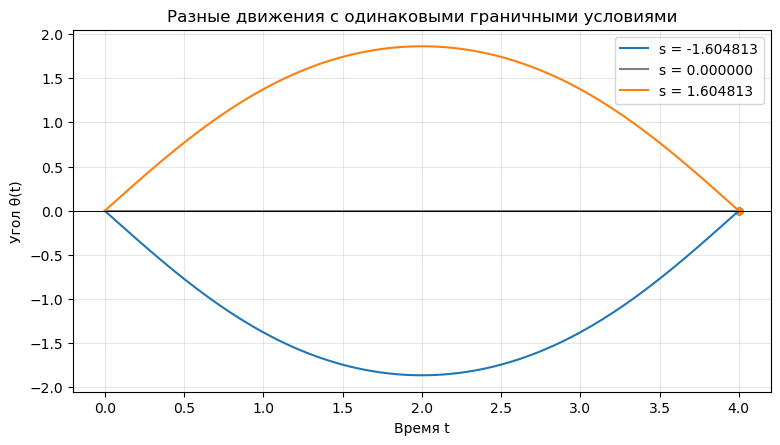

In [9]:
trajectory_colors = ['tab:blue', 'tab:gray', 'tab:orange']
trajectories = []
fig, ax = plt.subplots()
for j, s in enumerate(roots):
    t, theta = rk4(s, T_nonlin, 0.01, nonlinear=True, trajectory=True)
    trajectories.append((t, theta))
    ax.plot(t, theta, color=trajectory_colors[j], label=f's = {s:.6f}')
    ax.scatter([T_nonlin], [theta[-1]], color=trajectory_colors[j], s=24)
ax.axhline(0, color='black', linewidth=0.7)
ax.set(xlabel='Время t', ylabel='Угол θ(t)', title='Разные движения с одинаковыми граничными условиями')
ax.legend()
plt.show()

### 3.2. Зависимость метода Ньютона от начального приближения

Метод Ньютона локальный: его результат зависит от начального $s_0$. Для карты результатов берём много стартовых значений. Если итерации выходят слишком далеко, производная почти нулевая или достигнут предел числа шагов, фиксируем остановку.

Чтобы построить карту быстрее, сразу интегрируем множество задач Коши с разными скоростями. Схема RK4 остаётся той же, но вычисления выполняются над массивами.

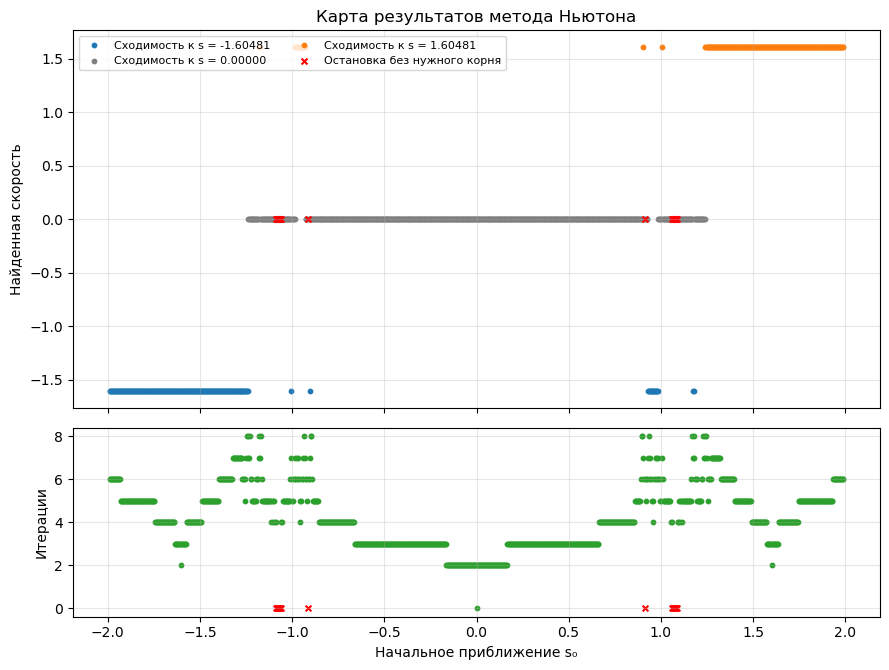

Итоги для 1001 начальных приближений:
сошёлся        985
большой шаг     16


In [10]:
def residual_many(s, h=h_nonlin):
    s = np.asarray(s, dtype=float)
    n = int(np.ceil(T_nonlin / h))
    dt = T_nonlin / n
    theta = np.zeros_like(s)
    omega = s.copy()
    for _ in range(n):
        a1, b1 = omega, -np.sin(theta)
        a2, b2 = omega + dt*b1/2, -np.sin(theta + dt*a1/2)
        a3, b3 = omega + dt*b2/2, -np.sin(theta + dt*a2/2)
        a4, b4 = omega + dt*b3, -np.sin(theta + dt*a3)
        theta += dt*(a1 + 2*a2 + 2*a3 + a4)/6
        omega += dt*(b1 + 2*b2 + 2*b3 + b4)/6
    return theta

initial_guesses = np.linspace(-1.99, 1.99, 1001)
current = initial_guesses.copy()
state = np.full(len(current), 'в процессе', dtype=object)
iters = np.full(len(current), -1, dtype=int)

for k in range(21):
    active = np.flatnonzero(state == 'в процессе')
    if not len(active):
        break
    x = current[active]
    r = residual_many(x)
    finished = np.abs(r) < 1e-9
    state[active[finished]] = 'сошёлся'
    iters[active[finished]] = k
    active, x, r = active[~finished], x[~finished], r[~finished]
    if not len(active) or k == 20:
        break
    d = (residual_many(x + 1e-5) - residual_many(x - 1e-5))/(2e-5)
    bad_d = (~np.isfinite(d)) | (np.abs(d) < 1e-9)
    state[active[bad_d]] = 'малая производная'
    ok_indices = active[~bad_d]
    new_values = x[~bad_d] - r[~bad_d] / d[~bad_d]
    escaped = (~np.isfinite(new_values)) | (np.abs(new_values) > 20)
    state[ok_indices[escaped]] = 'большой шаг'
    current[ok_indices[~escaped]] = new_values[~escaped]

state[state == 'в процессе'] = 'предел итераций'
root_index = np.full(len(current), -1, dtype=int)
for j, r in enumerate(roots):
    root_index[(state == 'сошёлся') & (np.abs(current-r) < 1e-4)] = j
state[(state == 'сошёлся') & (root_index == -1)] = 'другой корень'

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.8), sharex=True,
                             gridspec_kw={'height_ratios': [2, 1]})
for j, root in enumerate(roots):
    m = root_index == j
    ax1.scatter(initial_guesses[m], current[m], s=10, color=trajectory_colors[j],
                label=f'Сходимость к s = {root:.5f}')
m = root_index == -1
ax1.scatter(initial_guesses[m], np.zeros(m.sum()), s=18, color='red', marker='x',
            label='Остановка без нужного корня')
ax1.set(ylabel='Найденная скорость', title='Карта результатов метода Ньютона')
ax1.legend(loc='upper left', fontsize=8, ncol=2)
valid = root_index != -1
ax2.scatter(initial_guesses[valid], iters[valid], color='tab:green', s=10)
ax2.scatter(initial_guesses[~valid], np.zeros(np.sum(~valid)), color='red', marker='x', s=17)
ax2.set(xlabel='Начальное приближение s₀', ylabel='Итерации')
plt.tight_layout()
plt.show()
print('Итоги для', len(initial_guesses), 'начальных приближений:')
print(pd.Series(state).value_counts().to_string())

In [11]:
# Несколько конкретных запусков Ньютона для сравнения
sample_guesses = [-1.9, -1.2, -0.3, 0.0, 0.3, 1.2, 1.9]
newton_rows = []
for s0 in sample_guesses:
    found, history, status = newton(residual_nonlin, s0, tol=1e-9)
    matched = roots[np.argmin(np.abs(roots-found))] if np.isfinite(found) else np.nan
    result = f'{matched:.6f}' if status == 'сошёлся' and abs(matched-found)<1e-4 else status
    newton_rows.append([s0, len(history)-1, result])
display(pd.DataFrame(newton_rows, columns=['Старт s₀', 'Итерации', 'Результат']))

,Старт s₀,Итерации,Результат
0,-1.9,5,-1.604813
1,-1.2,5,0.000000
2,-0.3,3,0.000000
3,0.0,0,0.000000
4,0.3,3,0.000000
5,1.2,5,0.000000
6,1.9,5,1.604813


### 3.3. Проверка устойчивости при уменьшении шага

Для каждого шага $h$ заново ищем **положительный ненулевой корень**. За эталон принимаем RK4 с очень мелким шагом $h_{\mathrm{ref}}=4/16384$. Сравниваем как начальную скорость, так и всю траекторию.

,Шаг h,Подобранная скорость,Ошибка скорости,Макс. ошибка угла
0,0.250000,1.604807,6.236891e-06,4.981409e-05
1,0.125000,1.604812,7.824647e-07,3.110544e-06
2,0.062500,1.604813,6.086861e-08,1.931450e-07
3,0.031250,1.604813,4.170391e-09,1.201753e-08
4,0.015625,1.604813,2.719398e-10,7.491050e-10


Эталонная положительная скорость: 1.604813034777


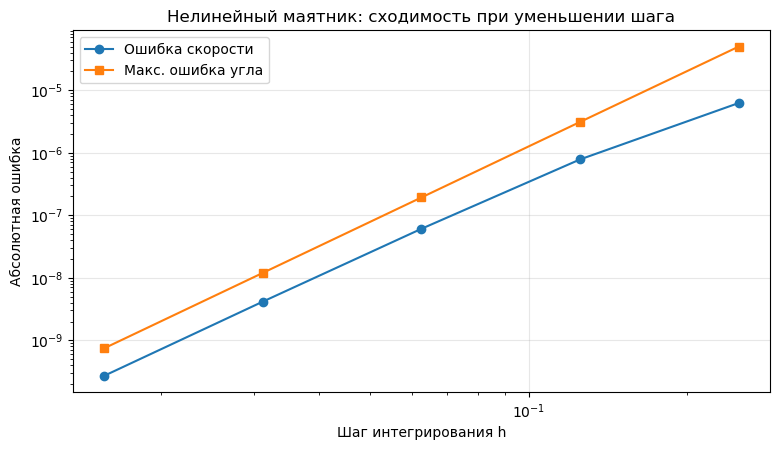

In [12]:
steps_nonlin = [0.25, 0.125, 0.0625, 0.03125, 0.015625]
h_ref = 4 / 16384
s_ref = brentq(lambda s: residual_nonlin(s, h_ref), 1.3, 1.85, xtol=1e-13)
t_ref, theta_ref = rk4(s_ref, T_nonlin, h_ref, nonlinear=True, trajectory=True)

nonlinear_rows = []
for h in steps_nonlin:
    s_h = brentq(lambda s: residual_nonlin(s, h), 1.3, 1.85, xtol=1e-12)
    t_h, theta_h = rk4(s_h, T_nonlin, h, nonlinear=True, trajectory=True)
    stride = (len(t_ref)-1) // (len(t_h)-1)
    theta_ref_on_grid = theta_ref[::stride]
    nonlinear_rows.append([h, s_h, abs(s_h-s_ref),
                           np.max(np.abs(theta_h-theta_ref_on_grid))])
nonlinear_accuracy = pd.DataFrame(nonlinear_rows,
    columns=['Шаг h', 'Подобранная скорость', 'Ошибка скорости', 'Макс. ошибка угла'])
display(nonlinear_accuracy)
print(f'Эталонная положительная скорость: {s_ref:.12f}')

fig, ax = plt.subplots()
ax.loglog(nonlinear_accuracy['Шаг h'], nonlinear_accuracy['Ошибка скорости'], 'o-', label='Ошибка скорости')
ax.loglog(nonlinear_accuracy['Шаг h'], nonlinear_accuracy['Макс. ошибка угла'], 's-', label='Макс. ошибка угла')
ax.set(xlabel='Шаг интегрирования h', ylabel='Абсолютная ошибка',
       title='Нелинейный маятник: сходимость при уменьшении шага')
ax.legend()
plt.show()

## 4. Анимация найденных движений

Слева одновременно показаны три маятника, справа — их углы. Для всех движений используется **общая временная шкала** $0\leqslant t\leqslant4$. Вертикальная линия и маркеры справа двигаются синхронно с маятниками.



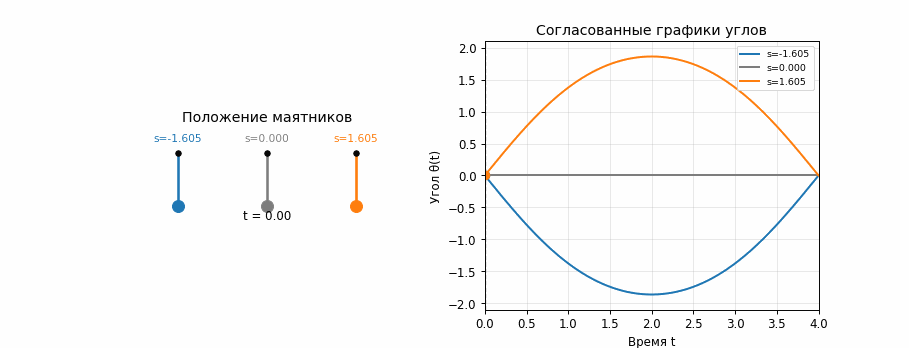

In [13]:
fig, (ax_p, ax_t) = plt.subplots(1, 2, figsize=(10.7, 4.1),
                              gridspec_kw={'width_ratios': [1.15, 1.25]})
pivots = [-1.45, 0.0, 1.45]
rod_length = 0.85
lines, bobs, angle_marks = [], [], []

for j, (s, (ts, angles)) in enumerate(zip(roots, trajectories)):
    color = trajectory_colors[j]
    ax_p.scatter([pivots[j]], [0], color='black', s=20, zorder=3)
    rod, = ax_p.plot([], [], lw=2.2, color=color)
    bob, = ax_p.plot([], [], 'o', ms=10, color=color)
    lines.append(rod)
    bobs.append(bob)
    ax_p.text(pivots[j], 0.19, f's={s:.3f}', ha='center', fontsize=9, color=color)
    ax_t.plot(ts, angles, color=color, linewidth=1.7, label=f's={s:.3f}')
    dot, = ax_t.plot([], [], 'o', color=color, ms=7)
    angle_marks.append(dot)

ax_p.set(xlim=(-2.5, 2.5), ylim=(-1.12, 0.4), title='Положение маятников')
ax_p.set_aspect('equal', adjustable='box')
ax_p.axis('off')
ax_t.set(xlim=(0, T_nonlin), ylim=(-2.1, 2.1), xlabel='Время t',
         ylabel='Угол θ(t)', title='Согласованные графики углов')
ax_t.legend(loc='upper right', fontsize=8)
vertical = ax_t.axvline(0, color='black', linestyle='--', linewidth=1)
time_text = ax_p.text(0, -1.07, '', ha='center')
frames = np.linspace(0, T_nonlin, 85)

def update(t):
    vertical.set_xdata([t, t])
    for j, (ts, angles) in enumerate(trajectories):
        theta = float(np.interp(t, ts, angles))
        x = pivots[j] + rod_length * np.sin(theta)
        y = -rod_length * np.cos(theta)
        lines[j].set_data([pivots[j], x], [0, y])
        bobs[j].set_data([x], [y])
        angle_marks[j].set_data([t], [theta])
    time_text.set_text(f't = {t:.2f}')
    return lines + bobs + angle_marks + [vertical, time_text]

animation = FuncAnimation(fig, update, frames=frames, interval=85, blit=False, repeat=True)
with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, 'pendulum.gif')
    animation.save(path, writer=PillowWriter(fps=12), dpi=85)
    with open(path, 'rb') as f:
        embedded_gif = f.read()
plt.close(fig)
display(Image(data=embedded_gif, format='gif'))

## 5. Выводы

1. В линейной задаче найденная скорость близка к точному значению $s=0.2/\sin2$. Ньютон обычно требует меньше итераций, но при численной производной каждая итерация обходится дороже.
2. Уменьшение шага RK4 улучшает точность траектории. Один только строгий допуск корня не устраняет погрешность интегрирования.
3. В нелинейной задаче на заданном отрезке имеются три скорости, приводящие к $\theta(4)=0$: нулевая и две противоположные ненулевые. Одинаковые начальное и конечное положения не задают единственного движения, поскольку начальная скорость не зафиксирована.
4. Ньютон может сходиться к разным корням в зависимости от стартового значения. Для надёжного нахождения всех решений можно сначала просмотреть невязку и выделить интервалы со сменой знака.